# 🍄 Pipeline de treino e avaliação com MLflow: base Mushroom

## 1. Apresentação do projeto
**Problema:** classificar cogumelos como **comestíveis** ou **venenosos** a partir das suas características. É uma classificação **binária**.

**Objetivo da atividade:** montar um pipeline organizado de **treino → validação → seleção → teste**, com cada execução rastreada no MLflow.

**Tecnologias:** Python 3.12 · pandas · scikit-learn (MLP, Árvore, Random Forest) · MLflow 3.16 (runs, métricas, artefatos, traces) · Jupyter

> Este notebook **não treina modelos**. Ele lê os resultados reais registrados no MLflow pelo `main.py`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from IPython.display import Image, display

# Raiz do projeto (funciona abrindo o notebook pela pasta notebooks/ ou pela raiz)
RAIZ = Path.cwd() if (Path.cwd() / "main.py").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

from src import config
from src.exploracao import carregar_dados
from src.preparacao import criar_preprocessador, dividir_dados, preparar_dados

mlflow.set_tracking_uri(config.URI_RASTREAMENTO)
cliente = mlflow.MlflowClient()
experimento = cliente.get_experiment_by_name(config.NOME_EXPERIMENTO_MLFLOW)
print("Experimento MLflow:", config.NOME_EXPERIMENTO_MLFLOW,
      "| encontrado" if experimento else "| NÃO encontrado: rode  python main.py")

Experimento MLflow: mushroom-aula08 | encontrado


## 2. Conhecendo o dataset
- **Origem:** UCI Machine Learning Repository, base *Mushroom*
- **Alvo (`class`):** `e` = *edible* (comestível) · `p` = *poisonous* (venenoso)
- **Atributos:** 22 características categóricas, cada uma representada por uma letra

In [2]:
df = carregar_dados()
print(f"{df.shape[0]} registros | {df.shape[1]} colunas (1 alvo + {df.shape[1] - 1} atributos)")
display(df.head(3))
display(df["class"].value_counts().rename({"e": "comestível (e)", "p": "venenoso (p)"}).to_frame("quantidade"))

8124 registros | 23 colunas (1 alvo + 22 atributos)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m


,quantidade
class,
comestível (e),4208
venenoso (p),3916


## 3. Preparação dos dados
| Etapa | Decisão | Por quê |
|---|---|---|
| `veil-type` | removida | tem o mesmo valor em todas as linhas |
| `?` em `stalk-root` | vira a categoria `ausente` | evita apagar cerca de 30% das linhas |
| Letras | One-Hot (colunas de 0 e 1) | a rede neural só entende números |
| Divisão | 60% treino · 20% validação · 20% teste, estratificada, semente 42 | o treino ensina, a validação escolhe e o teste confirma |

⚠️ O pré-processamento **aprende só com o treino**. Assim, a validação e o teste não "vazam" para dentro do modelo.

In [3]:
print("Valores '?' por coluna:", (df == "?").sum()[lambda s: s > 0].to_dict())

X, y = preparar_dados(df)
X_treino, X_validacao, X_teste, y_treino, y_validacao, y_teste = dividir_dados(X, y)
display(pd.DataFrame({
    "linhas": [len(y_treino), len(y_validacao), len(y_teste)],
    "% venenosos": [round(p.mean() * 100, 2) for p in (y_treino, y_validacao, y_teste)],
}, index=["treino", "validação", "teste"]))

preprocessador = criar_preprocessador(X_treino.columns).fit(X_treino)   # fit só no treino
print("Colunas depois do One-Hot:", len(preprocessador.get_feature_names_out()))

Valores '?' por coluna: {'stalk-root': 2480}


,linhas,% venenosos
treino,4874,48.22
validação,1625,48.18
teste,1625,48.18


Colunas depois do One-Hot: 116


## 4. Modelo utilizado
O modelo principal é uma **MLP** (rede neural *Multilayer Perceptron*) do **scikit-learn** (`MLPClassifier`). **Não** usamos PyTorch.

```
116 entradas (One-Hot)  →  32 neurônios (ReLU)  →  1 saída (probabilidade de ser venenoso)
```

- **Otimizador:** Adam, com a taxa de aprendizado `learning_rate_init`
- **Regularização L2:** `alpha`
- **Treino por épocas:** cada chamada de `partial_fit` é **uma época**. Ao fim de cada época, medimos `train_loss`, `val_loss` e `val_accuracy`.

A **Árvore de Decisão** e a **Random Forest** entram só como **referência**. Elas treinam de uma vez, sem épocas, então não têm curvas e não participam da seleção.

## 5. Configurações experimentais
Cada MLP muda **um único parâmetro** em relação à `mlp-base`. Valores lidos do MLflow:

In [4]:
# Última execução completa do pipeline = última run "avaliacao-final"
final = cliente.search_runs([experimento.experiment_id], "tags.papel = 'avaliacao_final'",
                            order_by=["start_time DESC"], max_results=1)
if not final:
    raise RuntimeError("Nenhuma avaliação final encontrada. Rode no terminal:  python main.py")
final = final[0]
id_execucao = final.data.tags["id_execucao"]
runs = cliente.search_runs([experimento.experiment_id],
                           f"tags.id_execucao = '{id_execucao}' and tags.papel != 'avaliacao_final'",
                           order_by=["start_time ASC"])
print("Execução analisada:", id_execucao, "|", len(runs), "runs de treino + 1 avaliação final")

colunas = ["modelo", "hidden_layer_sizes", "learning_rate_init", "alpha", "epocas", "max_depth", "n_estimators"]
configs = pd.DataFrame({r.info.run_name: {c: r.data.params.get(c, "–") for c in colunas} for r in runs}).T
configs.insert(0, "papel", [r.data.tags["papel"] for r in runs])
configs

Execução analisada: 2026-10-10_19-59-25 | 5 runs de treino + 1 avaliação final


,papel,modelo,hidden_layer_sizes,learning_rate_init,alpha,epocas,max_depth,n_estimators
mlp-base,candidato,MLPClassifier,"(32,)",0.001,0.0001,30,–,–
mlp-lr-alta,candidato,MLPClassifier,"(32,)",0.01,0.0001,30,–,–
mlp-l2-alta,candidato,MLPClassifier,"(32,)",0.001,0.1,30,–,–
ref-arvore-decisao,referencia,DecisionTreeClassifier,–,–,–,–,5,–
ref-random-forest,referencia,RandomForestClassifier,–,–,–,–,None,100


## 6. Pipeline e MLflow
```
python main.py
  ├─ run mlp-base ──────────┐
  ├─ run mlp-lr-alta        │  cada run: preparação → pré-processamento → treino → VALIDAÇÃO
  ├─ run mlp-l2-alta        │
  ├─ run ref-arvore-decisao │
  ├─ run ref-random-forest ─┘
  ├─ seleção: maior val_f1, desempate pelo menor val_loss (só validação)
  └─ run avaliacao-final: a escolhida é avaliada UMA vez no TESTE
```
| Tipo | O que é registrado |
|---|---|
| **Parâmetros** | modelo, hiperparâmetros, épocas, semente, proporções, origem dos dados, pré-processamento |
| **Métricas** | por época (`train_loss`, `val_loss`, `val_accuracy`) e finais (`val_f1`…; `test_*` só na avaliação final) |
| **Artefatos** | curvas, matriz de confusão, relatório, `configuracao.json`, modelo treinado |
| **Traces** | uma etapa (*span*) para cada fase do pipeline, com a duração |

In [5]:
exemplo = runs[0]
print(f"Artefatos da run '{exemplo.info.run_name}':",
      [a.path for a in cliente.list_artifacts(exemplo.info.run_id)])

trace = mlflow.search_traces(locations=[experimento.experiment_id], run_id=exemplo.info.run_id,
                             return_type="list")[0]
pd.DataFrame([{"etapa (span)": s.name, "duração (ms)": round((s.end_time_ns - s.start_time_ns) / 1e6)}
              for s in trace.data.spans])

Artefatos da run 'mlp-base': ['configuracao.json', 'curvas_treinamento.png', 'historico_epocas.json', 'matriz_confusao_validacao.png', 'relatorio_validacao.txt']


,etapa (span),duração (ms)
0,pipeline:mlp-base,6908
1,preparacao_dados,1644
2,preprocessamento,133
3,treinamento,4853
4,validacao,55


## 7. Comparação das runs (validação)

In [6]:
metricas = ["val_accuracy", "val_precision", "val_recall", "val_f1", "val_loss", "epoca_val_accuracy_maxima"]
comparacao = pd.DataFrame({r.info.run_name: {m: r.data.metrics.get(m) for m in metricas} for r in runs}).T
comparacao.style.format({m: "{:.4f}" for m in metricas[:4]} | {"val_loss": "{:.6f}", "epoca_val_accuracy_maxima": "{:.0f}"}, na_rep="–")

,val_accuracy,val_precision,val_recall,val_f1,val_loss,epoca_val_accuracy_maxima
mlp-base,1.0000,1.0000,1.0000,1.0000,0.000351,4
mlp-lr-alta,1.0000,1.0000,1.0000,1.0000,0.000016,2
mlp-l2-alta,1.0000,1.0000,1.0000,1.0000,0.005519,4
ref-arvore-decisao,1.0000,1.0000,1.0000,1.0000,–,–
ref-random-forest,1.0000,1.0000,1.0000,1.0000,–,–


Curvas lidas do histórico de métricas do MLflow (step = época):

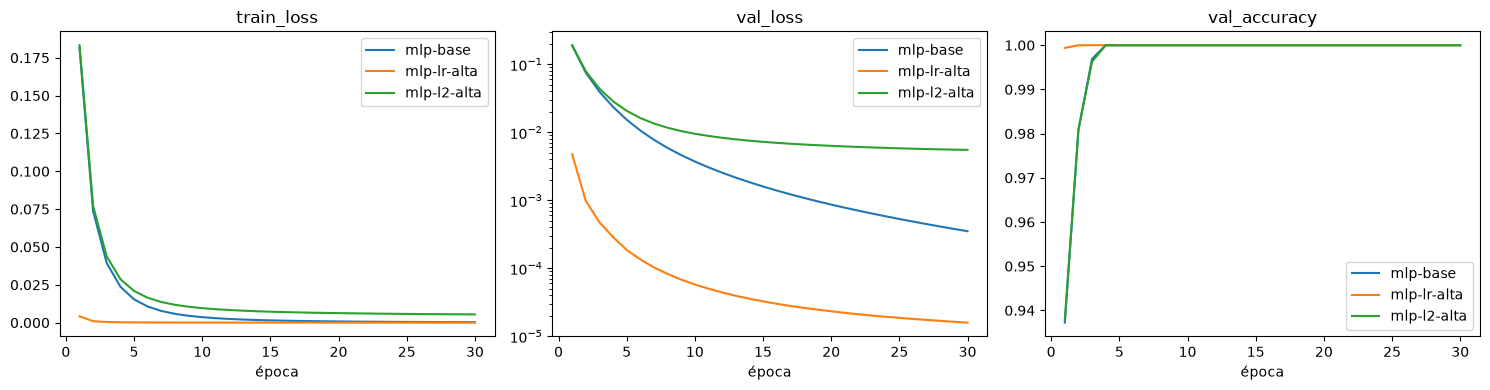

In [7]:
mlps = [r for r in runs if r.data.params.get("modelo") == "MLPClassifier"]
fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
for eixo, metrica in zip(eixos, ["train_loss", "val_loss", "val_accuracy"]):
    for r in mlps:
        historico = cliente.get_metric_history(r.info.run_id, metrica)
        eixo.plot([h.step for h in historico], [h.value for h in historico], label=r.info.run_name)
    eixo.set_title(metrica)
    eixo.set_xlabel("época")
    eixo.legend()
eixos[1].set_yscale("log")   # escala log: as diferenças pequenas ficam visíveis
plt.tight_layout()
plt.show()

**Como ler os gráficos:**
- A `mlp-lr-alta` (taxa de aprendizado 10x maior) converge muito mais rápido.
- A `mlp-l2-alta` termina com o `val_loss` mais alto, porque a regularização forte "segura" os pesos.
- Treino e validação ficam juntos, então **não há sinal de overfitting**.

## 8. Escolha da configuração
A escolha usou **somente a validação**. Justificativa gravada pelo pipeline:

In [8]:
caminho = cliente.download_artifacts(final.info.run_id, "selecao.json")
selecao = json.loads(Path(caminho).read_text(encoding="utf-8"))
print(selecao["justificativa"])
print("\nRun escolhida marcada com a tag selecionada=sim:",
      [r.info.run_name for r in runs if r.data.tags.get("selecionada") == "sim"])

Critério: maior val_f1; desempate: menor val_loss (somente validação).
Escolhida: mlp-lr-alta (val_f1=1.0000, val_loss=0.000016, val_accuracy máxima na época 2).
Comparada: mlp-base (val_f1=1.0000, val_loss=0.000351, val_accuracy máxima na época 4).
Comparada: mlp-l2-alta (val_f1=1.0000, val_loss=0.005519, val_accuracy máxima na época 4).

Run escolhida marcada com a tag selecionada=sim: ['mlp-lr-alta']


Todas as MLPs empataram em F1 = 1.0 na validação, então o desempate foi pelo **menor `val_loss`**: o modelo que erra com menos "confiança errada".

## 9. Avaliação final no conjunto de teste
O teste foi usado **uma única vez**, só com a configuração escolhida. Os valores abaixo vêm da run `avaliacao-final`:

Configuração avaliada: mlp-lr-alta


,teste
test_accuracy,1.0
test_precision,1.0
test_recall,1.0
test_f1,1.0


                precision    recall  f1-score   support

comestível (e)     1.0000    1.0000    1.0000       842
  venenoso (p)     1.0000    1.0000    1.0000       783

      accuracy                         1.0000      1625
     macro avg     1.0000    1.0000    1.0000      1625
  weighted avg     1.0000    1.0000    1.0000      1625



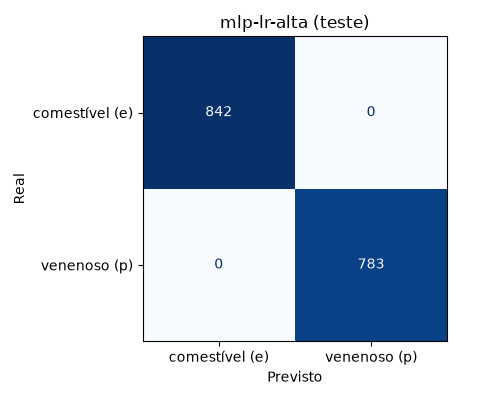

In [9]:
print("Configuração avaliada:", final.data.tags["run_escolhida_nome"])
display(pd.Series({k: v for k, v in final.data.metrics.items()}).round(4).to_frame("teste"))
print(Path(cliente.download_artifacts(final.info.run_id, "relatorio_teste.txt")).read_text(encoding="utf-8"))
display(Image(cliente.download_artifacts(final.info.run_id, "matriz_confusao_teste.png")))

## 10. Conclusão
**O que os experimentos mostraram**
- Uma MLP simples (32 neurônios) classifica 100% da validação e do teste corretamente.
- A **taxa de aprendizado** foi o parâmetro com mais efeito: com 0,01, a validação chega ao máximo na época 2, contra a época 4 da base.
- A **L2 forte** (0,1) não piorou a acurácia, mas deixou o modelo menos confiante (`val_loss` maior).

**Limitações**
- A base é quase perfeitamente separável (o cheiro sozinho já resolve a maioria dos casos), então todos os modelos chegam a 100%.
- Só uma divisão de dados (semente 42) e só 3 configurações de MLP foram testadas.

**Próximos passos**
- Repetir com várias sementes (`python main.py --semente N`) para ver se os resultados se mantêm.
- Testar a MLP com menos atributos (por exemplo, sem `odor`) para ter um problema mais difícil.

## 11. Reprodução
```powershell
.venv\Scripts\activate
pip install -r requirements.txt
python main.py                                   # 5 runs + seleção + teste final
python main.py --help                            # opções (épocas, lr, L2, arquitetura, semente...)
mlflow ui --backend-store-uri sqlite:///mlflow.db
```
Interface: http://127.0.0.1:5000 → experimento **mushroom-aula08** (abas *Runs*, *Traces* e *Models*).